# AI4I: EDA y evidencia reproducible

8.000 observaciones sintéticas de aula, 271 positivas (3,3875%). El objetivo es
clasificar el estado actual. Las muestras SMB se conservan aparte. No existen
fechas de entrenamiento ni una identidad física de máquina verificada.

Este cuaderno usa los mismos módulos que las herramientas, no otra preparación.
Las métricas nuevas son desarrollo; el test del PR29 ya fue inspeccionado.

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd() if Path("data/ai4i2020_train.csv").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [1]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from scoring.preparation import features, split_development

frame = pd.read_csv(ROOT / "data/ai4i2020_train.csv")
print("rows:", len(frame), "positives:", int(frame.machine_failure.sum()))
print("missing cells:", int(frame.isna().sum().sum()))
display(frame.describe().round(2))

rows: 8000 positives: 271
missing cells: 0


,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,machine_failure,failure_TWF,failure_HDF,failure_PWF,failure_OSF,failure_RNF
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.01,310.01,1539.36,40.00,107.68,0.03,0.00,0.01,0.01,0.01,0.00
std,2.00,1.48,180.98,10.02,63.61,0.18,0.07,0.10,0.10,0.10,0.04
min,295.30,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,298.30,308.80,1422.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,300.10,310.10,1503.00,40.10,107.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,301.50,311.10,1613.00,46.80,163.00,0.00,0.00,0.00,0.00,0.00,0.00
max,304.50,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


## Distribución y clases

Una accuracy del 96,61% se obtiene prediciendo siempre 0, pero con recall 0.
Por eso comparamos AP, recall, precisión, F2 y matrices de confusión.

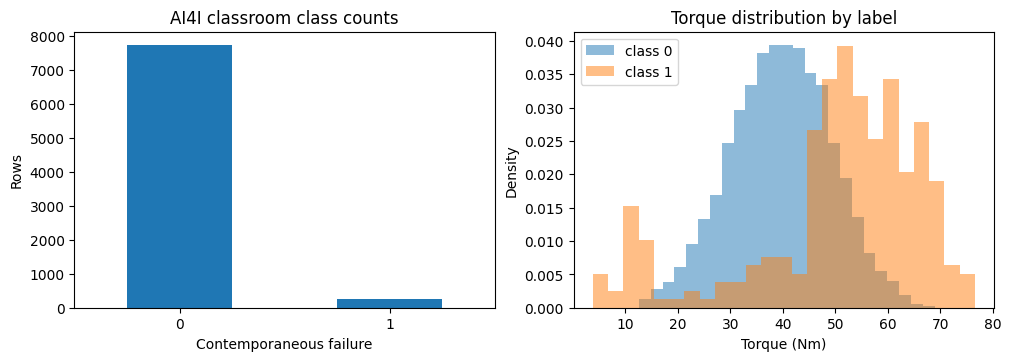

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
frame.machine_failure.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(
    title="AI4I classroom class counts", xlabel="Contemporaneous failure", ylabel="Rows"
)
for label, group in frame.groupby("machine_failure"):
    axes[1].hist(
        group.torque_Nm, bins=25, alpha=0.5, density=True, label=f"class {label}"
    )
axes[1].set(
    title="Torque distribution by label", xlabel="Torque (Nm)", ylabel="Density"
)
axes[1].legend()
plt.show()

## Features físicas y split

Diferencia térmica en K; potencia mecánica ideal en W; desgaste×par es un proxy.
No entran etiquetas, subtipos, timestamps ni machine_id al modelo. NiFi deberá
validar las entradas antes de inferir; la imputación del modelo no valida sensores.

In [3]:
display(features(frame).describe().round(2))
train, validation, excluded = split_development(frame)
print(
    {
        "train": len(train),
        "validation": len(validation),
        "old_test_excluded": len(excluded),
    }
)
print("Type diagnostics (not worker demographics):")
display(frame.groupby("machine_type").machine_failure.agg(["count", "sum", "mean"]))

,air_temp_K,process_temp_K,rpm,torque_Nm,tool_wear_min,temp_diff,power_W,wear_torque
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.0,8000.00,8000.00
mean,300.01,310.01,1539.36,40.00,107.68,10.0,6282.62,4302.68
std,2.00,1.48,180.98,10.02,63.61,1.0,1072.42,2820.18
min,295.30,305.70,1168.00,3.80,0.00,7.6,1148.44,0.00
25%,298.30,308.80,1422.00,33.20,53.00,9.3,5559.61,1953.32
50%,300.10,310.10,1503.00,40.10,107.00,9.8,6272.29,3998.70
75%,301.50,311.10,1613.00,46.80,163.00,11.0,7013.87,6265.05
max,304.50,313.80,2886.00,76.60,253.00,12.1,10469.92,16497.00


{'train': 5600, 'validation': 1200, 'old_test_excluded': 1200}
Type diagnostics (not worker demographics):


,count,sum,mean
machine_type,,,
H,789,16,0.020279
L,4830,197,0.040787
M,2381,58,0.024360


## Histórico SMB conservado

Ejecutar antes `uv run --frozen python -m scripts.build_history`.
Los cuatro snapshots tienen 40 filas, todas negativas. Agrupar machine_id muestra
observaciones del simulador, no una historia física ni un conjunto independiente.

In [4]:
with duckdb.connect() as con:
    display(
        con.execute(
            "SELECT machine_id, count(*) n, sum(machine_failure) positives FROM read_parquet(?) GROUP BY machine_id ORDER BY n DESC, machine_id",
            [str(ROOT / "historical/silver/**/*.parquet")],
        ).df()
    )

,machine_id,n,positives
0,CNC-039,4,0.0
1,CNC-049,4,0.0
2,CNC-005,3,0.0
3,CNC-040,3,0.0
4,CNC-001,2,0.0
5,CNC-010,2,0.0
6,CNC-025,2,0.0
7,CNC-028,2,0.0
8,CNC-038,2,0.0
9,CNC-047,2,0.0


## Interpretación y reproducción

No corregimos los subtipos mediante OR: las discrepancias se auditan en CG02.
El RF elegido y los umbrales están en docs/evidence/CG08_results.json y CG10_results.json.
Los módulos ejecutables guardan seed, versiones, hash, folds y limitaciones.
La estacionalidad generada en scripts/seasonal_lab.py es un escenario inventado
con censoring y purga temporal; no convierte AI4I en predicción real a 24h.

Pendientes: revisión por otro miembro, prueba de integración viva y datos finales
independientes. No se puede certificar el nivel 10 solo con estos artefactos.